In [12]:
import h5py
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.mixture import GaussianMixture
from scipy.special import erf
from scipy.optimize import least_squares
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the '3d' projection
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path
import time

In [13]:
base_dir      = Path("/Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology/Fracture Flow UROP")
# transport_dir = base_dir / "Updated Code" / "transport narrowed param ranges"
transport_dir = base_dir / "Updated Code" / "transport"
mat_path = transport_dir / "all_trial_bkt_data.mat"

In [14]:
# Reused from the sibling percentile-BKT notebooks -- keep in sync if those
# notebooks' loader changes.
def load_all_trial_bkt_data(mat_path, ps_indices=None):
    param_sets = {}
    with h5py.File(mat_path, 'r') as f:
        weights = f['weights'][()].T  # (num_param_sets, 3)
        atbd = f['all_trial_bkt_data']  # (1, N) object refs
        indices = ps_indices if ps_indices is not None else range(atbd.shape[1])
        for i in indices:
            ps_grp = f[atbd[0, i]]
            if 'p0' in ps_grp:
                p0 = float(ps_grp['p0'][()].flat[0])
            else:
                # The OG "transport" dataset (original, non-narrowed param
                # ranges -- cell-1 points here) stores connectivity as
                # connected_fraction instead of p0; p0 (disconnected
                # probability) is just its complement. Everything downstream
                # of this loader still only ever sees p0.
                p0 = 1.0 - float(ps_grp['connected_fraction'][()].flat[0])
            td = ps_grp['trial_data']
            trial_data = []
            for j in range(td.shape[1]):
                arr = f[td[0, j]][()]
                trial_data.append(arr.flatten() if arr.dtype == np.float64 else np.array([], dtype=np.float64))
            param_sets[i] = {'p0': p0, 'trial_data': trial_data}
    return param_sets, weights


def recover_theta(w):
    """Raw [0,1] weight -> physical theta. OG param ranges (matches
    Updated Code/transport, per info_outputs_varying_parameters.m -- NOT the
    narrowed-range bounds used by the "transport narrowed param ranges"
    dataset elsewhere in this project): disc in [0.1, 5] (was [1, 2.1]
    narrowed), length_ratio in [0.02, 0.5] (was [0.3, 0.5] narrowed); b is
    unchanged, [0.01e-3, 0.3e-3] in both."""
    disc = 5*w[0] + 0.1*(1 - w[0])            # [0.1, 5]
    b    = 0.01e-3*w[1] + 0.3e-3*(1 - w[1])   # [0.01e-3, 0.3e-3]
    lr   = 0.02*w[2] + 0.5*(1 - w[2])         # [0.02, 0.5]
    return disc, lr, b


def quantile_bkt(bkt, p, Np):
    """pth-percentile breakthrough time for one trial from its raw particle
    arrival times (order statistic), or None if undefined. Copied from
    [per p] distrib of pth percentile bkt.ipynb."""
    k = int(np.floor(p * Np))
    if k < len(bkt):
        return bkt[k]
    return None


def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

In [15]:
# Same connectivity filter as the sibling notebooks.
P0_THRESHOLD = 0.9
Np = 1000

with h5py.File(mat_path, 'r') as f:
    n_param_sets = f['all_trial_bkt_data'].shape[1]

all_param_sets, weights = load_all_trial_bkt_data(mat_path, range(n_param_sets))
USABLE_PS = sorted(i for i, ps in all_param_sets.items() if ps['p0'] < P0_THRESHOLD)
ps_by_p0 = sorted(USABLE_PS, key=lambda i: all_param_sets[i]['p0'])
print(f"{len(USABLE_PS)} / {n_param_sets} param sets usable (p0 < {P0_THRESHOLD})")

60 / 100 param sets usable (p0 < 0.9)


In [16]:
# --- New approach: learn the joint CDF surface F(theta, p, log t) directly,
# instead of fitting a parametric family (2-Gaussian mixture / skew-logistic)
# at each (theta,p) and training a network to predict that family's
# coefficients. Motivated by the joint-surface plots in the sibling notebook
# ("[per p] joint CDF surface F(theta,p,logt).ipynb"), which show the whole
# family of percentile-BKT CDFs forms one smooth, coherent surface in
# (p, log t) rather than a set of unrelated curves -- suggesting a single
# network that takes (theta, p, log t) as input and outputs F directly
# should be able to learn that surface without needing an intermediate
# distributional-family assumption at all.
#
# For each param set: imagine drawing the percentile vs BKT curve for each network
# and putting 1s below the curve and 0s above the curve. Average over all networks.
#
# Training data: for each (theta,p) group (same p_vals grid used
# elsewhere), the empirical CDF is exact at the trials' own order
# statistics -- (log10(t_i), ecdf_i) for i=1..n, ecdf_i=(i-0.5)/n -- no
# parametric fitting step in between. Flatten ALL of these (theta,p,log t)
# -> ecdf rows, across every usable group, into one big supervised
# regression dataset. Each group's n order statistics are highly redundant
# (adjacent sorted values differ by very little in ecdf), so each group is
# subsampled down to at most MAX_PER_GROUP evenly-spaced-by-RANK points
# (preserves the full ecdf range 0->1 and the tail behavior, just drops
# redundant middle density) to keep the flattened dataset a manageable size
# for training.
p_vals = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3,
                    0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95])
MIN_SAMPLES = 20
MAX_PER_GROUP = 80


def group_ecdf(ps_idx, p):
    """Empirical (log10(t), ecdf) order-statistic pairs for one (theta,p)
    group -- the raw ingredient both this cell's flattened training set and
    the cross-model sse comparison cell are built from, factored out here so
    that shared logic (pull per-trial percentile-BKT values, drop Nones,
    apply MIN_SAMPLES, sort, compute plotting-position ecdf) lives in one
    place instead of two. Returns None if too few samples; otherwise
    (log_vals, ecdf), both length n, FULL (not yet subsampled) -- callers
    that want MAX_PER_GROUP-subsampled rows (like the training-data loop
    below) subsample after calling this; callers that want the full
    empirical curve (like the sse comparison) use it as-is."""
    ps = all_param_sets[ps_idx]
    vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]  # each bkt is a 1D array of t values; then vals[network k] is the pth percentile BKT for network k, right?
    vals = np.array([v for v in vals if v is not None])
    if len(vals) < MIN_SAMPLES:
        return None
    log_vals = np.sort(np.log10(vals))
    n = len(log_vals)  # the number of networks that had a non-None pth percentile BKT
    ecdf = (np.arange(1, n + 1) - 0.5) / n  # so the lowest empirical pth-percentile BKT displays a probability of 0.5/#networks having attained p% by that BKT, the highest gets a probability of (n-.5)/n
    return log_vals, ecdf


rows = []
for ps_idx in USABLE_PS:
    disc, lr, b = recover_theta(weights[ps_idx])
    for p in p_vals:
        result = group_ecdf(ps_idx, p)
        if result is None:
            continue
        log_vals, ecdf = result
        n = len(log_vals)
        if n > MAX_PER_GROUP:
            keep = np.linspace(0, n - 1, MAX_PER_GROUP).round().astype(int)
            keep = np.unique(keep)
            log_vals, ecdf = log_vals[keep], ecdf[keep]
        for lt, f in zip(log_vals, ecdf):
            rows.append((ps_idx, disc, lr, b, p, lt, f))

flat_df = pd.DataFrame(rows, columns=['paramset_idx', 'discspacing', 'length_ratio', 'b', 'p', 'logt', 'ecdf'])
print(f"Flattened dataset: {len(flat_df)} rows from {flat_df['paramset_idx'].nunique()} param sets "
      f"x up to {len(p_vals)} p_vals x up to {MAX_PER_GROUP} order statistics/group")

Flattened dataset: 81600 rows from 60 param sets x up to 17 p_vals x up to 80 order statistics/group


In [17]:
# Inputs: (discspacing, length_ratio, b, logit(p), log10(t)) -- FIVE
# continuous inputs this time (vs. the 4 used in the sibling notebooks,
# which only needed theta+p since t was handled analytically by whichever
# parametric CDF family). Output: a single scalar F in [0,1] via a sigmoid
# last layer (guarantees a valid-range CDF value for any input, same spirit
# as the constrained-output-transform trick used elsewhere, just architecturally
# built in this time instead of applied post-hoc).
#
# Train/val split is BY PARAM SET, not by row -- a lesson learned the hard
# way in the skew-logistic notebook's monotonicity experiment: a row-random
# split lets nearly every theta appear in both train and val (just at
# different p/log t), which is an easier "interpolate for an already-seen
# theta" task, not genuine generalization to new theta. Splitting by whole
# param sets is the honest test, and comparable to how the monotonicity
# experiment's model_nopenalty/model_mono were evaluated.
FEATURE_COLS = ['discspacing', 'length_ratio', 'b', 'p', 'logt']

X_all = np.column_stack([
    flat_df['discspacing'].values, flat_df['length_ratio'].values, flat_df['b'].values,
    logit(flat_df['p'].values), flat_df['logt'].values,
]).astype(np.float64)
y_all = flat_df['ecdf'].values.astype(np.float64)

X_mean, X_std = X_all.mean(axis=0), X_all.std(axis=0)


def normalize_X(X):
    return (X - X_mean) / X_std


X_norm = normalize_X(X_all).astype(np.float32)
y_all = y_all.astype(np.float32)

rng = np.random.default_rng(42)
all_ps = flat_df['paramset_idx'].unique()
val_ps = set(rng.choice(all_ps, size=max(1, int(0.2 * len(all_ps))), replace=False))
is_val = flat_df['paramset_idx'].isin(val_ps).values

X_train, y_train = X_norm[~is_val], y_all[~is_val]
X_val, y_val = X_norm[is_val], y_all[is_val]
print(f"train: {len(X_train)} rows ({(~is_val).sum() and flat_df.loc[~is_val, 'paramset_idx'].nunique()} param sets)  "
      f"val: {len(X_val)} rows ({flat_df.loc[is_val, 'paramset_idx'].nunique()} param sets)")


def build_model():
    l2_reg = 9e-5
    return keras.Sequential([
        keras.layers.Input(shape=(5,)),
        keras.layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(1, activation="sigmoid"),
    ])


def lr_by_epoch(epoch):
    if epoch < 80:
        return 1e-3
    elif epoch < 120:
        return 5e-4
    else:
        return 1e-4

train: 65280 rows (48 param sets)  val: 16320 rows (12 param sets)


In [18]:
# --- Unconstrained baseline: plain MSE regression, no physics penalty ---
model_plain = build_model()
model_plain.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
t0 = time.time()
history_plain = model_plain.fit(
    X_train, y_train, validation_data=(X_val, y_val), epochs=150, batch_size=512,
    callbacks=[keras.callbacks.LearningRateScheduler(lr_by_epoch, verbose=0)], verbose=0)
print(f"[{time.time()-t0:.0f}s] plain model -- final train loss: {history_plain.history['loss'][-1]:.5f}  "
      f"val loss: {history_plain.history['val_loss'][-1]:.5f}")
model_plain.save(transport_dir / 'direct_cdf_surface_model_plain.keras')

[16s] plain model -- final train loss: 0.00238  val loss: 0.04315


In [30]:
# --- Physics-constrained version: same data/split/architecture, plus two
# soft penalties enforced via autodiff on the network's own inputs
# (double-backprop / "collocation" style, as in physics-informed NNs):
#
#   dF/d(log t) >= 0   -- F must be non-decreasing in t (valid CDF)
#   dF/dp       <= 0   -- higher-percentile BKT distributions lie to the
#                         right of lower-percentile ones (physical ordering
#                         of order statistics), matching the corrected sign
#                         convention established in the skew-logistic
#                         notebook's monotonicity experiment: for p_i<p_j,
#                         F_{p_i}(t) >= F_{p_j}(t) everywhere.
#
# Both derivatives are taken directly on the Z-SCORED input columns (logit(p)
# and log t, both already z-scored into columns 3 and 4 of X_train) rather
# than converting back to physical units first -- unnecessary extra work,
# since z-scoring (x-mean)/std is a strictly increasing function of x for
# std>0, so the SIGN of dF/d(normalized column) is identical to the sign of
# dF/d(physical quantity). Only the sign matters for a hinge penalty.
#
# Unlike the skew-logistic notebook's monotonicity experiment -- which had
# to batch by param set and compare ADJACENT p rows within a batch, because
# that model only ever produced a CDF via a fitted parametric family evaluated
# at a handful of discrete p's -- this network takes (p, log t) as direct
# continuous inputs, so the constraint can be checked POINTWISE at each
# training row via its own input gradient. No special batching needed: plain
# row-shuffled minibatches work fine, exactly like the unconstrained baseline.
#
# lam_t/lam_p are passed as tf.constant ARGUMENTS to train_step, not read
# off Python globals -- @tf.function bakes plain Python float globals into
# the graph at first-trace time, so reassigning a global LAM_T afterward
# would silently have no effect on later calls.
#
# train_step is defined and @tf.function-decorated INSIDE train_constrained
# (a fresh closure per call), not once at module scope -- a single
# module-level @tf.function shared across multiple train_constrained() calls
# (as the LAM sweep below does, each with its own fresh model/optimizer)
# raises "tf.function only supports singleton tf.Variables created on the
# first call": the optimizer's slot variables are lazily created on the
# FIRST call ever traced, and every later call -- with a genuinely different
# model/opt object, needing genuinely different variables -- hits that same
# already-finalized trace and is refused permission to create new ones. A
# per-call closure means each train_constrained() call gets its own trace
# tied to its own model/opt, so variable creation only ever happens once
# per closure, exactly as tf.function requires.
IDX_P, IDX_LOGT = 3, 4  # columns of X_train corresponding to logit(p), logt (both z-scored)


def train_constrained(X_train, y_train, X_val, y_val, lam_t=1.0, lam_p=1.0, epochs=150, batch_size=512, verbose=0):
    model = build_model()
    opt = keras.optimizers.Adam(1e-3)
    lam_t_tf = tf.constant(lam_t, dtype=tf.float32)
    lam_p_tf = tf.constant(lam_p, dtype=tf.float32)

    @tf.function
    def train_step(X_batch, y_batch):
        with tf.GradientTape() as outer_tape:
            with tf.GradientTape() as inner_tape:
                inner_tape.watch(X_batch)
                F_pred = model(X_batch, training=True)
            dF_dX = inner_tape.gradient(F_pred, X_batch)  # (batch, 5), normalized-input-space partials

            data_loss = tf.reduce_mean(tf.square(y_batch - tf.squeeze(F_pred, axis=1)))
            penalty_t = tf.reduce_mean(tf.nn.relu(-dF_dX[:, IDX_LOGT]))  # want dF/d(logt) >= 0
            penalty_p = tf.reduce_mean(tf.nn.relu(dF_dX[:, IDX_P]))      # want dF/d(logit p) <= 0
            loss = data_loss + lam_t_tf * penalty_t + lam_p_tf * penalty_p

        grads = outer_tape.gradient(loss, model.trainable_variables)
        opt.apply_gradients(zip(grads, model.trainable_variables))
        return data_loss, penalty_t, penalty_p

    n = len(X_train)
    history = {'loss': [], 'val_loss': [], 'penalty_t': [], 'penalty_p': []}
    rng_local = np.random.default_rng(1)

    for epoch in range(epochs):
        opt.learning_rate.assign(lr_by_epoch(epoch))
        order = rng_local.permutation(n)
        ep_loss, ep_pt, ep_pp = [], [], []
        for i in range(0, n, batch_size):
            idx = order[i:i + batch_size]
            Xb = tf.constant(X_train[idx])
            yb = tf.constant(y_train[idx])
            dl, pt, pp = train_step(Xb, yb)
            ep_loss.append(float(dl)); ep_pt.append(float(pt)); ep_pp.append(float(pp))

        val_pred = model(X_val, training=False).numpy().squeeze(axis=1)
        val_loss = float(np.mean((y_val - val_pred) ** 2))
        history['loss'].append(np.mean(ep_loss))
        history['val_loss'].append(val_loss)
        history['penalty_t'].append(np.mean(ep_pt))
        history['penalty_p'].append(np.mean(ep_pp))
        if verbose and epoch % 25 == 0:
            print(f"epoch {epoch}: loss={history['loss'][-1]:.5f} val_loss={val_loss:.5f} "
                  f"pen_t={history['penalty_t'][-1]:.5f} pen_p={history['penalty_p'][-1]:.5f}")

    return model, history


t0 = time.time()
model_constrained, history_constrained = train_constrained(X_train, y_train, X_val, y_val, lam_t=3.0, lam_p=3.0, epochs=150, verbose=0)  # lam=3.0 chosen from the LAM_SWEEP results below: best sse mean/median tradeoff alongside a low (0.19%) monotonicity violation rate
print(f"[{time.time()-t0:.0f}s] constrained model -- final train loss: {history_constrained['loss'][-1]:.5f}  "
      f"val loss: {history_constrained['val_loss'][-1]:.5f}  "
      f"penalty_t: {history_constrained['penalty_t'][-1]:.5f}  penalty_p: {history_constrained['penalty_p'][-1]:.5f}")
model_constrained.save(transport_dir / 'direct_cdf_surface_model_constrained.keras')


[18s] constrained model -- final train loss: 0.00008  val loss: 0.05460  penalty_t: 0.00000  penalty_p: 0.00000


In [27]:
# --- Cross-model comparison metric: same "CDF-space sse against the FULL
# (non-subsampled) empirical order statistics per group" reported in all
# three sibling notebooks -- lets this approach's fit quality be compared
# apples-to-apples against the PDF/MLE baseline (mean sse 0.1015), the
# CDF/2-erf mixture (0.0386), and the CDF/skew-logistic (0.0928) models.
def group_sse(predict_fn):
    sses = []
    for ps_idx in USABLE_PS:
        disc, lr, b = recover_theta(weights[ps_idx])
        for p in p_vals:
            result = group_ecdf(ps_idx, p)  # full (non-subsampled) order statistics -- see cell-4
            if result is None:
                continue
            log_vals, ecdf = result
            n = len(log_vals)
            X_g = normalize_X(np.column_stack([
                np.full(n, disc), np.full(n, lr), np.full(n, b), np.full(n, logit(p)), log_vals,
            ])).astype(np.float32)
            F_pred = predict_fn(X_g)
            sses.append(np.sum((F_pred - ecdf) ** 2))  # same convention as sibling notebooks: sum of squared residuals over that group's own (full, non-subsampled) points
    return np.array(sses)


sse_plain = group_sse(lambda X: model_plain.predict(X, verbose=0).squeeze(axis=1))
sse_constrained = group_sse(lambda X: model_constrained(X, training=False).numpy().squeeze(axis=1))

print("Direct-CDF-surface NN, PLAIN (unconstrained):       sse mean=%.4f  median=%.4f  max=%.4f" %
      (sse_plain.mean(), np.median(sse_plain), sse_plain.max()))
print("Direct-CDF-surface NN, CONSTRAINED (physics penalty): sse mean=%.4f  median=%.4f  max=%.4f" %
      (sse_constrained.mean(), np.median(sse_constrained), sse_constrained.max()))
print("\nFor reference (from the sibling notebooks' own conclusion cells):")
print("  PDF/MLE baseline (2-Gaussian mixture, MLE):      sse mean=0.1015")
print("  CDF/2-erf mixture (2-Gaussian mixture, CDF-LS):  sse mean=0.0386")
print("  CDF/skew-logistic (single S-curve, CDF-LS):      sse mean=0.0928")

Direct-CDF-surface NN, PLAIN (unconstrained):       sse mean=8.3371  median=0.1681  max=243.9906
Direct-CDF-surface NN, CONSTRAINED (physics penalty): sse mean=10.6699  median=0.0469  max=298.6374

For reference (from the sibling notebooks' own conclusion cells):
  PDF/MLE baseline (2-Gaussian mixture, MLE):      sse mean=0.1015
  CDF/2-erf mixture (2-Gaussian mixture, CDF-LS):  sse mean=0.0386
  CDF/skew-logistic (single S-curve, CDF-LS):      sse mean=0.0928


In [28]:
# --- Monotonicity violation check on a fine grid, for a few representative
# param sets -- same style of check as the skew-logistic notebook's
# before/after comparison, but here checking the ACTUAL constraint the
# training penalty targets (sign of finite-difference slopes in p and in
# log t across a fine grid), for both the plain and constrained models.
n_ps = len(ps_by_p0)
REP_PS_IDX = [ps_by_p0[0], ps_by_p0[n_ps // 4], ps_by_p0[n_ps // 2],
              ps_by_p0[3 * n_ps // 4], ps_by_p0[-1]]
P_GRID = np.linspace(0.02, 0.95, 60)


def compute_grid(predict_fn, ps_idx):
    ps = all_param_sets[ps_idx]
    disc, lr, b = recover_theta(weights[ps_idx])
    all_logvals = []
    for p in [0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]:
        vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]
        vals = np.array([v for v in vals if v is not None])
        if len(vals):
            all_logvals.append(np.log10(vals))
    all_logvals = np.concatenate(all_logvals)
    t_lo, t_hi = all_logvals.min() - 0.3, all_logvals.max() + 0.3
    T_GRID = np.linspace(t_lo, t_hi, 150)

    Tm, Pm = np.meshgrid(T_GRID, P_GRID)  # both (n_p, n_t)
    X_grid = normalize_X(np.column_stack([
        np.full(Tm.size, disc), np.full(Tm.size, lr), np.full(Tm.size, b),
        logit(Pm.ravel()), Tm.ravel(),
    ])).astype(np.float32)
    Z = predict_fn(X_grid).reshape(Tm.shape)
    return T_GRID, Z


def violation_rates(predict_fn):
    frac_t_viol, frac_p_viol = [], []
    for ps_idx in REP_PS_IDX:
        T_GRID, Z = compute_grid(predict_fn, ps_idx)
        dZ_dt = np.diff(Z, axis=1)   # along log t (axis=1) -- want >= 0
        dZ_dp = np.diff(Z, axis=0)   # along p (axis=0) -- want <= 0
        frac_t_viol.append((dZ_dt < -1e-6).mean())
        frac_p_viol.append((dZ_dp > 1e-6).mean())
    return np.mean(frac_t_viol), np.mean(frac_p_viol)


t_viol_plain, p_viol_plain = violation_rates(lambda X: model_plain.predict(X, verbose=0).squeeze(axis=1))
t_viol_cons, p_viol_cons = violation_rates(lambda X: model_constrained(X, training=False).numpy().squeeze(axis=1))

print("Fraction of adjacent grid-cell steps violating each constraint (avg over 5 representative param sets):")
print(f"  PLAIN:       dF/d(logt)<0 (should be >=0): {100*t_viol_plain:.2f}%   "
      f"dF/dp>0 (should be <=0): {100*p_viol_plain:.2f}%")
print(f"  CONSTRAINED: dF/d(logt)<0 (should be >=0): {100*t_viol_cons:.2f}%   "
      f"dF/dp>0 (should be <=0): {100*p_viol_cons:.2f}%")

Fraction of adjacent grid-cell steps violating each constraint (avg over 5 representative param sets):
  PLAIN:       dF/d(logt)<0 (should be >=0): 0.00%   dF/dp>0 (should be <=0): 0.45%
  CONSTRAINED: dF/d(logt)<0 (should be >=0): 0.00%   dF/dp>0 (should be <=0): 0.52%


In [ ]:
# --- Error score per theta: mean(|pred_F(q,t) - actual_F(q,t)| / (actual_F(q,t) + eps))
# over all the empirical (q,t) points for that theta (same full,
# non-subsampled points via group_ecdf used elsewhere in this notebook) --
# a single number summarizing how well model_plain/model_constrained's OWN
# (already-frozen, cells 6-7) predictions matched the real data for that
# param set, in RELATIVE terms. eps=1e-5 is just a floor to avoid literal
# division by zero (actual_F itself is always > 0, since it's an order-
# statistic ecdf value, but can get very close to 0 for the lowest-ranked
# point in a large group) -- not a smoothing term, so small-actual_F points
# can still dominate this average. No circularity: this is computed AFTER
# those models are trained, using their fixed predictions, so it's an
# ordinary fixed label for the small theta-only error-score model trained
# in the next cell.
REL_ERR_EPS = 1e-5

error_rows = []
for ps_idx in USABLE_PS:
    disc, lr, b = recover_theta(weights[ps_idx])
    for p in p_vals:
        result = group_ecdf(ps_idx, p)
        if result is None:
            continue
        log_vals, ecdf = result
        X_g = normalize_X(np.column_stack([
            np.full(len(log_vals), disc), np.full(len(log_vals), lr), np.full(len(log_vals), b),
            np.full(len(log_vals), logit(p)), log_vals,
        ])).astype(np.float32)
        rel_err_plain = np.abs(model_plain.predict(X_g, verbose=0).squeeze(axis=1) - ecdf) / (ecdf + REL_ERR_EPS)
        rel_err_constrained = np.abs(model_constrained(X_g, training=False).numpy().squeeze(axis=1) - ecdf) / (ecdf + REL_ERR_EPS)
        for re_p, re_c in zip(rel_err_plain, rel_err_constrained):
            error_rows.append((ps_idx, disc, lr, b, re_p, re_c))

error_pt_df = pd.DataFrame(error_rows, columns=['paramset_idx', 'discspacing', 'length_ratio', 'b',
                                                 'rel_err_plain', 'rel_err_constrained'])
error_score_df = error_pt_df.groupby('paramset_idx').agg(
    discspacing=('discspacing', 'first'), length_ratio=('length_ratio', 'first'), b=('b', 'first'),
    error_score_plain=('rel_err_plain', 'mean'), error_score_constrained=('rel_err_constrained', 'mean'),
).reset_index()

print(f"Computed error scores for {len(error_score_df)} param sets")
print("\nerror_score_plain summary:")
print(error_score_df['error_score_plain'].describe())
print("\nerror_score_constrained summary:")
print(error_score_df['error_score_constrained'].describe())


In [39]:
# --- Small theta -> error-score network(s): input is JUST theta (disc, lr,
# b) -- no p, no logt, since error_score is already aggregated over all
# (p,t) for a given theta. Own 3-dim normalization (separate from
# normalize_X's 5-dim theta+p+logt space, since the input dimensionality
# differs). Much smaller architecture than model_plain/model_constrained
# (only ~60 rows total here, one per usable param set, vs. the ~80K-row
# flattened dataset those were trained on) to avoid overfitting.
#
# TWO loss/output variants are trained side by side, per model (plain/
# constrained) -- kept both rather than picking one, so cell-10's plots can
# show predictions from each next to the true error score for a direct
# visual comparison:
#   'softplus': the original design -- softplus output (non-negative,
#     matches error_score being a mean of absolute values), plain MSE on
#     the raw error_score. error_score is heavily right-skewed (tight
#     low-error cluster + a few much-larger outliers), so plain MSE on the
#     raw target combined with L2 weight decay on this small a dataset
#     compresses predictions toward the bulk -- but it also produced the
#     best held-out RANK correlation of everything tried (verified:
#     plain's VAL spearman 0.59, vs <=0.13 for every log-space variant).
#   'huber': linear output, target = log(error_score), Huber loss
#     (delta=1.0) instead of MSE. Log-space fixes the TRAIN-set magnitude
#     compression (predictions land close to the true mean there) and
#     Huber (quadratic near 0, linear beyond delta) keeps the few
#     log-space outliers from dominating training the way plain MSE did in
#     an earlier (rejected) log+MSE attempt -- but VAL-set rank
#     correlation is still weaker than 'softplus' gets.
X_theta_all = np.column_stack([error_score_df['discspacing'].values, error_score_df['length_ratio'].values,
                                error_score_df['b'].values]).astype(np.float64)
Xt_mean, Xt_std = X_theta_all.mean(axis=0), X_theta_all.std(axis=0)


def normalize_X_theta(X):
    return (X - Xt_mean) / Xt_std


X_theta_norm = normalize_X_theta(X_theta_all).astype(np.float32)
# Same theta-level val split as Stage A (reuses the val_ps SET from cell-5).
is_val_theta = error_score_df['paramset_idx'].isin(val_ps).values
X_theta_train, X_theta_val = X_theta_norm[~is_val_theta], X_theta_norm[is_val_theta]

score_plain = error_score_df['error_score_plain'].values.astype(np.float32)
score_cons = error_score_df['error_score_constrained'].values.astype(np.float32)
log_score_plain = np.log(score_plain)
log_score_cons = np.log(score_cons)


def lr_by_epoch_small(epoch):
    if epoch < 150:
        return 1e-3
    elif epoch < 250:
        return 5e-4
    else:
        return 1e-4


def build_error_score_model(variant):
    l2_reg = 9e-5
    out_activation = "softplus" if variant == 'softplus' else None
    return keras.Sequential([
        keras.layers.Input(shape=(3,)),
        keras.layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg)),
        keras.layers.Dense(1, activation=out_activation),
    ])


def train_error_score_model(variant, y_all, name):
    y_train, y_val = y_all[~is_val_theta], y_all[is_val_theta]
    loss = "mse" if variant == 'softplus' else keras.losses.Huber(delta=1.0)
    model = build_error_score_model(variant)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss)
    t0 = time.time()
    hist = model.fit(X_theta_train, y_train, validation_data=(X_theta_val, y_val),
                      epochs=300, batch_size=16,
                      callbacks=[keras.callbacks.LearningRateScheduler(lr_by_epoch_small, verbose=0)], verbose=0)
    print(f"[{time.time()-t0:.0f}s] {name} ({variant}) -- final train loss: {hist.history['loss'][-1]:.5f}  "
          f"val loss: {hist.history['val_loss'][-1]:.5f}")
    model.save(transport_dir / f'{name}_{variant}.keras')
    return model


error_score_model_plain_softplus = train_error_score_model('softplus', score_plain, 'error_score_model_plain')
error_score_model_plain_huber = train_error_score_model('huber', log_score_plain, 'error_score_model_plain')
error_score_model_constrained_softplus = train_error_score_model('softplus', score_cons, 'error_score_model_constrained')
error_score_model_constrained_huber = train_error_score_model('huber', log_score_cons, 'error_score_model_constrained')


def predict_error_score(model, variant, X_theta_row_norm):
    """Predicted error score in ORIGINAL (not log) units, for either variant."""
    raw = model.predict(X_theta_row_norm, verbose=0).squeeze(axis=1)
    return raw if variant == 'softplus' else np.exp(raw)


[5s] error_score_model_plain (softplus) -- final train loss: 0.00222  val loss: 0.02560
[5s] error_score_model_plain (huber) -- final train loss: 0.10885  val loss: 1.17783
[5s] error_score_model_constrained (softplus) -- final train loss: 0.00303  val loss: 0.03171
[5s] error_score_model_constrained (huber) -- final train loss: 0.07012  val loss: 1.99546


[20s] lam=0  sse mean=9.5007  median=0.0543  dF/dp>0 violation rate=1.83%
[20s] lam=0.1  sse mean=10.9037  median=0.0514  dF/dp>0 violation rate=0.90%
[20s] lam=0.3  sse mean=13.5270  median=0.0438  dF/dp>0 violation rate=0.79%
[21s] lam=1  sse mean=11.5461  median=0.0446  dF/dp>0 violation rate=0.18%
[20s] lam=3  sse mean=17.0962  median=0.0433  dF/dp>0 violation rate=0.10%
[20s] lam=10  sse mean=9.5641  median=0.0461  dF/dp>0 violation rate=0.07%


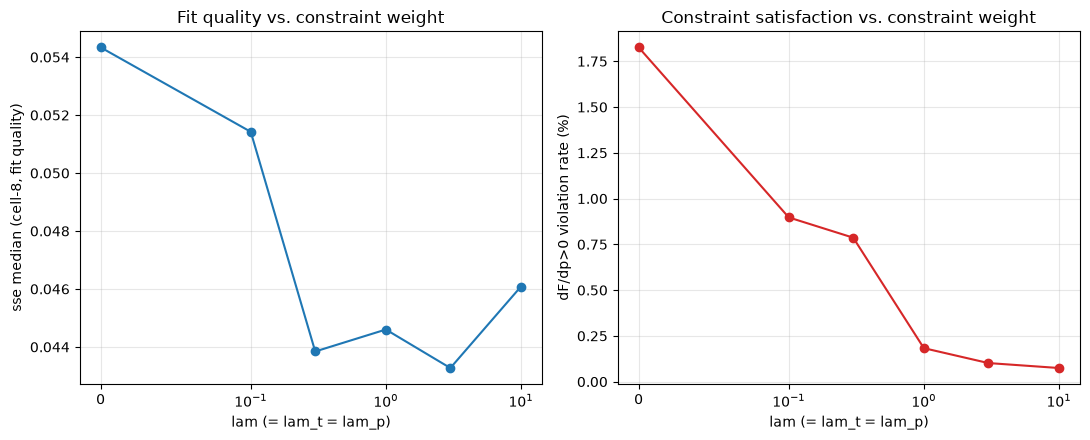

Saved /Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology/Fracture Flow UROP/Updated Code/transport/[per p, t] probability of >=p percent having bkt <= t, lam sweep.pdf
    lam   sse_mean  sse_median  p_viol_rate
0   0.0   9.500705    0.054336     0.018260
1   0.1  10.903710    0.051423     0.008972
2   0.3  13.527042    0.043844     0.007864
3   1.0  11.546128    0.044601     0.001831
4   3.0  17.096232    0.043273     0.001017
5  10.0   9.564083    0.046085     0.000746


In [ ]:
# # --- Physics-constraint weight sweep: retrain the constrained model fresh
# # for several values of lam (tying lam_t=lam_p=lam together -- a full 2D
# # grid over both weights independently would be 2x the retrains for a
# # tradeoff this notebook only needs a 1D picture of), then plot fit
# # quality (group_sse mean, cell-8) against constraint satisfaction
# # (dF/dp>0 violation rate, cell-9) as functions of lam. lam=0 is included
# # as the "no constraint at all" reference point (should behave like
# # model_plain, modulo random init).
# LAM_SWEEP = [0.0, 0.1, 0.3, 1.0, 3.0, 10.0]

# sweep_rows = []
# for lam in LAM_SWEEP:
#     t0 = time.time()
#     model_lam, _ = train_constrained(X_train, y_train, X_val, y_val, lam_t=lam, lam_p=lam, epochs=150, verbose=0)
#     predict_fn_lam = lambda X, m=model_lam: m(X, training=False).numpy().squeeze(axis=1)
#     sse_lam = group_sse(predict_fn_lam)
#     _, p_viol_lam = violation_rates(predict_fn_lam)
#     sweep_rows.append((lam, sse_lam.mean(), np.median(sse_lam), p_viol_lam))
#     print(f'[{time.time()-t0:.0f}s] lam={lam:g}  sse mean={sse_lam.mean():.4f}  median={np.median(sse_lam):.4f}  '
#           f'dF/dp>0 violation rate={100*p_viol_lam:.2f}%')

# sweep_df = pd.DataFrame(sweep_rows, columns=['lam', 'sse_mean', 'sse_median', 'p_viol_rate'])

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
# ax1.plot(sweep_df['lam'], sweep_df['sse_median'], 'o-', color='tab:blue')
# ax1.set_xscale('symlog', linthresh=0.1)
# ax1.set_xlabel('lam (= lam_t = lam_p)')
# ax1.set_ylabel('sse median (cell-8, fit quality)')
# ax1.set_title('Fit quality vs. constraint weight')
# ax1.grid(True, alpha=0.3)

# ax2.plot(sweep_df['lam'], 100 * sweep_df['p_viol_rate'], 'o-', color='tab:red')
# ax2.set_xscale('symlog', linthresh=0.1)
# ax2.set_xlabel('lam (= lam_t = lam_p)')
# ax2.set_ylabel('dF/dp>0 violation rate (%)')
# ax2.set_title('Constraint satisfaction vs. constraint weight')
# ax2.grid(True, alpha=0.3)

# plt.tight_layout()
# sweep_fig_path = transport_dir / '[per p, t] probability of >=p percent having bkt <= t, lam sweep.pdf'
# plt.savefig(sweep_fig_path, dpi=130, bbox_inches='tight')
# plt.show()
# print(f'Saved {sweep_fig_path}')
# print(sweep_df)


In [ ]:
# --- DISABLED: sibling parametric-model contexts (PDF/MLE baseline,
# CDF-erf mixture, CDF-logistic) -- commented out (not deleted) because
# these load percentile_erf_model.keras / percentile_cdf_erf_mixture_model.
# keras / percentile_cdf_skewlogistic_model.keras, all trained on the
# NARROWED param-range dataset. Since cell-1/cell-2 now point at the OG
# (non-narrowed) dataset, this cell would either crash (models not present
# in the OG transport_dir) or, if it found the files, silently feed them
# wildly out-of-distribution theta values (OG disc spans [0.1,5] vs.
# narrowed's [1,2.1]). Re-enable by removing the triple-quote wrapper below
# ONLY after those three models have been retrained on the OG dataset.
'''
def erf_mixture_cdf(x, w1, mu1, sigma1, mu2, sigma2):
    z1 = (x - mu1) / (sigma1 * np.sqrt(2))
    z2 = (x - mu2) / (sigma2 * np.sqrt(2))
    return w1 * 0.5 * (1 + erf(z1)) + (1 - w1) * 0.5 * (1 + erf(z2))


def genlogistic_cdf(x, mu, s, nu):
    z = (x - mu) / s
    return np.exp(-nu * np.logaddexp(0.0, -z))


def fit_gaussian_mixture_cdf(vals, n_init=5, seed=0):
    """PDF/MLE fit (2-component Gaussian mixture via sklearn EM) -- see
    "..., PDF fit - GMM and NN.ipynb" cell-5 for the full rationale."""
    x = np.log10(np.asarray(vals, dtype=float))
    x = x[np.isfinite(x)]
    if len(x) < 5:
        return None
    gm = GaussianMixture(n_components=2, random_state=seed, n_init=n_init, reg_covar=1e-6).fit(x.reshape(-1, 1))
    order = np.argsort(gm.means_.flatten())
    w = gm.weights_[order]
    mu = gm.means_.flatten()[order]
    sigma = np.sqrt(gm.covariances_.flatten()[order])
    w1, mu1, sigma1, mu2, sigma2 = w[0], mu[0], sigma[0], mu[1], sigma[1]
    xs = np.sort(x)
    n = len(xs)
    ecdf = (np.arange(1, n + 1) - 0.5) / n
    sse = np.sum((erf_mixture_cdf(xs, w1, mu1, sigma1, mu2, sigma2) - ecdf) ** 2)
    return {'w1': w1, 'mu1': mu1, 'sigma1': sigma1, 'mu2': mu2, 'sigma2': sigma2, 'sse': sse}


def fit_erf_mixture_cdf(vals, n_init=5, seed=0):
    """Direct CDF-least-squares fit (same 2-Gaussian-mixture family as
    fit_gaussian_mixture_cdf) -- see "..., CDF fit - ERF and NN.ipynb"
    cell-5 for the full rationale, including why mu/sigma are bounded."""
    x = np.sort(np.log10(np.asarray(vals, dtype=float)))
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 5:
        return None
    ecdf = (np.arange(1, n + 1) - 0.5) / n
    data_lo, data_hi = x[0], x[-1]
    data_range = max(data_hi - data_lo, 1e-3)
    mu_lo, mu_hi = data_lo - 3 * data_range, data_hi + 3 * data_range
    sigma_hi = 5 * data_range
    rng = np.random.default_rng(seed)

    def residuals(params):
        w1, mu1, sigma1, mu2, sigma2 = params
        return erf_mixture_cdf(x, w1, mu1, sigma1, mu2, sigma2) - ecdf

    best = None
    for _ in range(n_init):
        q = rng.uniform(0.15, 0.85)
        split = np.quantile(x, q)
        lo, hi = x[x <= split], x[x > split]
        mu1_0 = lo.mean() if len(lo) else x.mean()
        mu2_0 = hi.mean() if len(hi) else x.mean()
        sigma1_0 = max(lo.std(), 1e-3) if len(lo) else 1.0
        sigma2_0 = max(hi.std(), 1e-3) if len(hi) else 1.0
        w0 = np.clip(len(lo) / n, 0.05, 0.95)
        x0 = [w0, mu1_0, sigma1_0, mu2_0, sigma2_0]
        try:
            res = least_squares(residuals, x0,
                                 bounds=([0, mu_lo, 1e-6, mu_lo, 1e-6],
                                         [1, mu_hi, sigma_hi, mu_hi, sigma_hi]))
        except Exception:
            continue
        sse = np.sum(res.fun ** 2)
        if best is None or sse < best[0]:
            best = (sse, res.x)
    if best is None:
        return None
    sse, (w1, mu1, sigma1, mu2, sigma2) = best
    if mu1 > mu2:
        w1, mu1, sigma1, mu2, sigma2 = 1 - w1, mu2, sigma2, mu1, sigma1
    return {'w1': w1, 'mu1': mu1, 'sigma1': sigma1, 'mu2': mu2, 'sigma2': sigma2, 'sse': sse}


def fit_genlogistic_cdf(vals, n_init=8, seed=0, nu_hi=20.0):
    """Skew-logistic (Type I generalized logistic) fit -- see "..., CDF fit
    - logistic and NN.ipynb" cell-5 for the full rationale, including why
    nu_hi=20 despite ~42% of real fits hitting that bound."""
    x = np.sort(np.log10(np.asarray(vals, dtype=float)))
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 5:
        return None
    ecdf = (np.arange(1, n + 1) - 0.5) / n
    data_lo, data_hi = x[0], x[-1]
    data_range = max(data_hi - data_lo, 1e-3)
    mu_lo, mu_hi = data_lo - 3 * data_range, data_hi + 3 * data_range
    s_hi = 5 * data_range
    rng = np.random.default_rng(seed)

    def residuals(params):
        mu, s, nu = params
        return genlogistic_cdf(x, mu, s, nu) - ecdf

    best = None
    for _ in range(n_init):
        mu0 = np.median(x) + rng.uniform(-0.3, 0.3) * data_range
        s0 = max(x.std(), 1e-3) * rng.uniform(0.5, 1.5)
        nu0 = rng.uniform(0.3, 3.0)
        x0 = [mu0, s0, nu0]
        try:
            res = least_squares(residuals, x0, bounds=([mu_lo, 1e-6, 1e-3], [mu_hi, s_hi, nu_hi]))
        except Exception:
            continue
        sse = np.sum(res.fun ** 2)
        if best is None or sse < best[0]:
            best = (sse, res.x)
    if best is None:
        return None
    sse, (mu, s, nu) = best
    return {'mu': mu, 's': s, 'nu': nu, 'sse': sse}


def build_mixture_context(fit_fn, model_filename):
    """Shared context-builder for the two 5-parameter (w1,mu1,sigma1,mu2,
    sigma2) erf-mixture models (PDF/MLE baseline and CDF-erf mixture) --
    they differ only in fit_fn (MLE/EM vs. direct CDF least-squares).
    Reuses this notebook's own p_vals/MIN_SAMPLES (cell-4) -- identical
    grid used by both sibling notebooks when they trained these models."""
    records = []
    for ps_idx in USABLE_PS:
        ps = all_param_sets[ps_idx]
        disc, lr, b = recover_theta(weights[ps_idx])
        for p in p_vals:
            vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]
            vals = np.array([v for v in vals if v is not None])
            if len(vals) < MIN_SAMPLES:
                continue
            fit = fit_fn(vals)
            if fit is None:
                continue
            records.append({'paramset_idx': ps_idx, 'discspacing': disc, 'length_ratio': lr, 'b': b, 'p': p, **fit})
    fit_df_ctx = pd.DataFrame(records)

    TARGET_COLS = ['w1', 'mu1', 'sigma1', 'mu2', 'sigma2']

    def transform_Y(Y):
        w1, mu1, sigma1, mu2, sigma2 = Y[:, 0], Y[:, 1], Y[:, 2], Y[:, 3], Y[:, 4]
        w1c = np.clip(w1, 1e-4, 1 - 1e-4)
        return np.column_stack([np.log(w1c / (1 - w1c)), mu1, np.log(sigma1), mu2, np.log(sigma2)])

    def inverse_transform_Y(Yt):
        lw1, mu1, lsigma1, mu2, lsigma2 = Yt[:, 0], Yt[:, 1], Yt[:, 2], Yt[:, 3], Yt[:, 4]
        w1 = 1 / (1 + np.exp(-lw1))
        return np.column_stack([w1, mu1, np.exp(lsigma1), mu2, np.exp(lsigma2)])

    X_all_ctx = np.column_stack([fit_df_ctx[['discspacing', 'length_ratio', 'b']].values, logit(fit_df_ctx['p'].values)])
    Y_all_ctx = transform_Y(fit_df_ctx[TARGET_COLS].values)
    Xm, Xs = X_all_ctx.mean(axis=0), X_all_ctx.std(axis=0)
    Ym, Ys = Y_all_ctx.mean(axis=0), Y_all_ctx.std(axis=0)

    def normalize_X_ctx(X):
        return (X - Xm) / Xs

    def denormalize_Y_ctx(Y):
        return inverse_transform_Y(Y * Ys + Ym)

    model_ctx = keras.models.load_model(transport_dir / model_filename, compile=False)
    return {'cdf_fn': erf_mixture_cdf, 'normalize_X': normalize_X_ctx, 'denormalize_Y': denormalize_Y_ctx, 'model': model_ctx}


def build_logistic_context(model_filename):
    """Context-builder for the 3-parameter (mu,s,nu) skew-logistic model."""
    records = []
    for ps_idx in USABLE_PS:
        ps = all_param_sets[ps_idx]
        disc, lr, b = recover_theta(weights[ps_idx])
        for p in p_vals:
            vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]
            vals = np.array([v for v in vals if v is not None])
            if len(vals) < MIN_SAMPLES:
                continue
            fit = fit_genlogistic_cdf(vals)
            if fit is None:
                continue
            records.append({'paramset_idx': ps_idx, 'discspacing': disc, 'length_ratio': lr, 'b': b, 'p': p, **fit})
    fit_df_ctx = pd.DataFrame(records)

    TARGET_COLS = ['mu', 's', 'nu']

    def transform_Y(Y):
        mu, s, nu = Y[:, 0], Y[:, 1], Y[:, 2]
        return np.column_stack([mu, np.log(s), np.log(nu)])

    def inverse_transform_Y(Yt):
        mu, ls, lnu = Yt[:, 0], Yt[:, 1], Yt[:, 2]
        return np.column_stack([mu, np.exp(ls), np.exp(lnu)])

    X_all_ctx = np.column_stack([fit_df_ctx[['discspacing', 'length_ratio', 'b']].values, logit(fit_df_ctx['p'].values)])
    Y_all_ctx = transform_Y(fit_df_ctx[TARGET_COLS].values)
    Xm, Xs = X_all_ctx.mean(axis=0), X_all_ctx.std(axis=0)
    Ym, Ys = Y_all_ctx.mean(axis=0), Y_all_ctx.std(axis=0)

    def normalize_X_ctx(X):
        return (X - Xm) / Xs

    def denormalize_Y_ctx(Y):
        return inverse_transform_Y(Y * Ys + Ym)

    model_ctx = keras.models.load_model(transport_dir / model_filename, compile=False)
    return {'cdf_fn': genlogistic_cdf, 'normalize_X': normalize_X_ctx, 'denormalize_Y': denormalize_Y_ctx, 'model': model_ctx}


ctx_pdf_mle = build_mixture_context(fit_gaussian_mixture_cdf, 'percentile_erf_model.keras')
print("Built PDF/MLE baseline context")
ctx_cdf_erf = build_mixture_context(fit_erf_mixture_cdf, 'percentile_cdf_erf_mixture_model.keras')
print("Built CDF-erf-mixture context")
ctx_cdf_logistic = build_logistic_context('percentile_cdf_skewlogistic_model.keras')
print("Built CDF-logistic context")


def compute_grid_parametric(ctx, ps_idx):
    """Same t-grid logic as compute_grid above, but for a 'sibling'
    parametric model: predict this model's own (theta,p)-conditioned
    params ONCE per p (not per (p,logt) grid point, since t only enters
    analytically via cdf_fn), then evaluate the model's own cdf_fn across
    the shared T_GRID."""
    ps = all_param_sets[ps_idx]
    disc, lr, b = recover_theta(weights[ps_idx])
    all_logvals = []
    for p in [0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]:
        vals = [quantile_bkt(bkt, p, Np) for bkt in ps['trial_data']]
        vals = np.array([v for v in vals if v is not None])
        if len(vals):
            all_logvals.append(np.log10(vals))
    all_logvals = np.concatenate(all_logvals)
    t_lo, t_hi = all_logvals.min() - 0.3, all_logvals.max() + 0.3
    T_GRID = np.linspace(t_lo, t_hi, 150)

    X_grid = np.array([[disc, lr, b, logit(p)] for p in P_GRID])
    Y_pred = ctx['denormalize_Y'](ctx['model'].predict(ctx['normalize_X'](X_grid), verbose=0))
    Z = np.stack([ctx['cdf_fn'](T_GRID, *params) for params in Y_pred], axis=0)
    return T_GRID, Z
'''

In [ ]:
# --- Visual comparison: empirical F, predicted F, and relative error
# |pred_F(q,t) - actual_F(q,t)| / (actual_F(q,t) + eps), one row per
# representative param set (REP_PS_IDX, cell-9). Same eps=1e-5 floor (not a
# smoothing term -- just avoids literal division by zero) and same
# formula used for the "error score" in 71aaab88/error_score_df, so the
# score annotated in this plot's title is directly the mean of the colors
# shown in its own error panel. Only 3 columns now (empirical / predicted /
# error) -- an earlier version also had a separate absolute-error column,
# but with a single relative-error definition there's no need for both.
#
# The error panel's title shows only this TRUE error score -- the
# theta-only error-score NN's own predicted values (softplus/huber
# variants, see a5c1ff0b/d6b2f857/errscatter01) are intentionally left out
# of this plot; that comparison lives in its own dedicated diagnostic
# cells instead.
#
# Empirical points use P_GRID (cell-9's fine 60-point percentile grid used
# for the predicted-F surface itself), not the coarse 17-point p_vals
# training grid -- group_ecdf can compute the empirical (log t, q) curve
# for ANY q (it just re-derives per-trial percentile-BKT values at that q),
# so nothing stops the empirical scatter from being as dense as the
# predicted surface's own grid, giving a much richer empirical picture per
# param set than the training grid alone would.
#
# Colorbars are shared ACROSS ROWS (one per column, not one per panel): the
# predicted-F column already shares a fixed [0,1] scale, and the error
# column's colorbar vmax is capped at the 95th percentile of relative error
# across every row (not the true max) purely for VISUAL legibility -- a
# handful of points near actual_F=0 can have relative error orders of
# magnitude larger than everywhere else with eps this small (1e-5), and
# would otherwise wash out the color scale for every other point. The
# reported error SCORE itself (title annotation, error_score_df) is always
# the true, uncapped mean -- only the plotted color scale is capped.


def style_axis_2d(ax, T_GRID):
    tick_lo, tick_hi = int(np.floor(T_GRID.min())), int(np.ceil(T_GRID.max()))
    ticks = np.arange(tick_lo, tick_hi + 1)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'$10^{{{t:.0f}}}$' for t in ticks], fontsize=12)
    ax.set_xlim(T_GRID.min(), T_GRID.max())
    ax.set_xlabel('breakthrough time (s)', fontsize=14)
    ax.set_ylabel('percentile $q$', fontsize=14)
    ax.tick_params(labelsize=12)


CONTOUR_LEVELS = [0.1, 0.3, 0.5, 0.7, 0.9]
P_EMPIRICAL_GRID = P_GRID  # dense empirical percentile grid, shared with the predicted-surface grid (cell-9)


def plot_model_comparison(predict_fn, model_name, filename_suffix):
    # --- pass 1: gather every row's data first, so the error colorbar can be scaled globally ---
    row_data = []
    for ps_idx in REP_PS_IDX:
        ps = all_param_sets[ps_idx]
        disc, lr, b = recover_theta(weights[ps_idx])

        emp_logt, emp_p, emp_ecdf, emp_rel_err = [], [], [], []
        for p in P_EMPIRICAL_GRID:
            result = group_ecdf(ps_idx, p)
            if result is None:
                continue
            log_vals, ecdf = result
            X_g = normalize_X(np.column_stack([
                np.full(len(log_vals), disc), np.full(len(log_vals), lr), np.full(len(log_vals), b),
                np.full(len(log_vals), logit(p)), log_vals,
            ])).astype(np.float32)
            F_pred = predict_fn(X_g)
            emp_logt.append(log_vals)
            emp_p.append(np.full(len(log_vals), p))
            emp_ecdf.append(ecdf)
            emp_rel_err.append(np.abs(F_pred - ecdf) / (ecdf + REL_ERR_EPS))
        emp_logt = np.concatenate(emp_logt)
        emp_p = np.concatenate(emp_p)
        emp_ecdf = np.concatenate(emp_ecdf)
        emp_rel_err = np.concatenate(emp_rel_err)
        error_score = emp_rel_err.mean()

        T_GRID, Z = compute_grid(predict_fn, ps_idx)
        row_data.append(dict(ps_idx=ps_idx, ps=ps, disc=disc, lr=lr, b=b, emp_logt=emp_logt, emp_p=emp_p,
                              emp_ecdf=emp_ecdf, emp_rel_err=emp_rel_err, error_score=error_score,
                              T_GRID=T_GRID, Z=Z))

    rel_err_max = max(np.percentile(np.concatenate([rd['emp_rel_err'] for rd in row_data]), 95), 1e-3)

    # --- pass 2: plot, with the error column sharing its (capped) scale across every row ---
    n_rows = len(row_data)
    fig, axes = plt.subplots(n_rows, 3, figsize=(17, 4.6 * n_rows), constrained_layout=True)
    mesh_pred = mesh_err = None
    for row, rd in enumerate(row_data):
        ax_emp, ax_pred, ax_err = axes[row]

        ax_emp.scatter(rd['emp_logt'], rd['emp_p'], c=rd['emp_ecdf'], cmap='viridis', vmin=0, vmax=1, s=4, linewidths=0, rasterized=True)
        ax_emp.set_ylim(0, 1)
        style_axis_2d(ax_emp, rd['T_GRID'])
        ax_emp.set_title(f'ps{rd["ps_idx"]} (p0={rd["ps"]["p0"]:.2f})  empirical F', fontsize=15)

        mesh_pred = ax_pred.pcolormesh(rd['T_GRID'], P_GRID, rd['Z'], shading='auto', cmap='viridis', vmin=0, vmax=1, rasterized=True)
        cs = ax_pred.contour(rd['T_GRID'], P_GRID, rd['Z'], levels=CONTOUR_LEVELS, colors='white', linewidths=1.0, alpha=0.8)
        ax_pred.clabel(cs, fmt='%.1f', fontsize=10, colors='white')
        style_axis_2d(ax_pred, rd['T_GRID'])
        ax_pred.set_title(f'predicted F ({model_name})', fontsize=15)

        mesh_err = ax_err.scatter(rd['emp_logt'], rd['emp_p'], c=rd['emp_rel_err'], cmap='viridis', vmin=0, vmax=rel_err_max, s=4, linewidths=0, rasterized=True)
        ax_err.set_ylim(0, 1)
        style_axis_2d(ax_err, rd['T_GRID'])
        ax_err.set_title(f'relative error, score={rd["error_score"]:.4f}', fontsize=14)

    cbar_pred = fig.colorbar(mesh_pred, ax=axes[:, 1].tolist(), pad=0.02, shrink=0.7, label='predicted $F$')
    cbar_err = fig.colorbar(mesh_err, ax=axes[:, 2].tolist(), pad=0.02, shrink=0.7,
                             label='relative error (colorbar capped at 95th pct)')
    cbar_pred.ax.tick_params(labelsize=12)
    cbar_pred.set_label('predicted $F$', fontsize=14)
    cbar_err.ax.tick_params(labelsize=12)
    cbar_err.set_label('relative error (colorbar capped at 95th pct)', fontsize=14)

    fig.suptitle(f'Empirical vs predicted vs relative error, {model_name} model', fontsize=19)
    fig_path = transport_dir / f'[per p, t] probability of >=p percent having bkt <= t, empirical vs predicted vs error ({filename_suffix}).png'
    plt.savefig(fig_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved {fig_path}')


plot_model_comparison(lambda X: model_plain.predict(X, verbose=0).squeeze(axis=1), 'plain', 'plain')
plot_model_comparison(lambda X: model_constrained(X, training=False).numpy().squeeze(axis=1), 'constrained', 'constrained')


In [ ]:
# --- Diagnostic: true error_score (computed directly from model_plain/
# model_constrained's own residuals) vs. each error-score model's own
# predicted value, for every usable param set, split by train/held-out-val
# -- the real test of whether theta alone carries a useful signal for
# predicting fit quality, or whether the model just regresses to the mean.
# Both loss/output variants (softplus, huber -- see a5c1ff0b) are shown as
# separate series on the same axes for direct comparison. error_score here
# is the mean RELATIVE error (see 71aaab88), not mean absolute error.
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
model_pairs = [
    ('plain', 'error_score_plain', error_score_model_plain_softplus, error_score_model_plain_huber),
    ('constrained', 'error_score_constrained', error_score_model_constrained_softplus, error_score_model_constrained_huber),
]
for ax, (name, true_col, model_sp, model_hb) in zip(axes, model_pairs):
    true = error_score_df[true_col].values
    pred_sp = predict_error_score(model_sp, 'softplus', X_theta_norm)
    pred_hb = predict_error_score(model_hb, 'huber', X_theta_norm)

    ax.scatter(true[~is_val_theta], pred_sp[~is_val_theta], s=24, alpha=0.6, color='tab:blue', marker='o', label='softplus, train')
    ax.scatter(true[is_val_theta], pred_sp[is_val_theta], s=48, alpha=0.9, color='tab:blue', marker='^', label='softplus, val')
    ax.scatter(true[~is_val_theta], pred_hb[~is_val_theta], s=24, alpha=0.6, color='tab:orange', marker='o', label='huber, train')
    ax.scatter(true[is_val_theta], pred_hb[is_val_theta], s=48, alpha=0.9, color='tab:orange', marker='^', label='huber, val')

    lims = [0, max(true.max(), pred_sp.max(), pred_hb.max()) * 1.05]
    ax.plot(lims, lims, 'k--', lw=1, alpha=0.5, label='y=x')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('true error score (mean relative error)', fontsize=14)
    ax.set_ylabel('predicted error score', fontsize=14)
    ax.set_title(name, fontsize=16)
    ax.tick_params(labelsize=12)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = transport_dir / '[per p, t] probability of >=p percent having bkt <= t, error score true vs predicted.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved {fig_path}')


In [ ]:
# --- Predicted error score vs. each raw theta input, mirroring
# GammaMixture.ipynb's "model output vs input variable" scatter grid
# (blue dots, one panel per (output, input) pair). Rows = model variant x
# loss variant [plain-softplus, plain-huber, constrained-softplus,
# constrained-huber], columns = theta input [discspacing, length_ratio,
# b]. Raw physical theta values on the x-axis (not normalized), same
# convention as GammaMixture.ipynb. Alpha/marker size bumped up from GMM's
# 0.05/1 (tuned for a ~100K-row dataset) since this dataset is only ~60
# param sets.
theta_param_names = ['discspacing', 'length_ratio', 'b']
error_score_variants = [
    ('plain, softplus', error_score_model_plain_softplus, 'softplus'),
    ('plain, huber', error_score_model_plain_huber, 'huber'),
    ('constrained, softplus', error_score_model_constrained_softplus, 'softplus'),
    ('constrained, huber', error_score_model_constrained_huber, 'huber'),
]

fig, axes = plt.subplots(nrows=len(error_score_variants), ncols=len(theta_param_names), figsize=(16, 18))
for j, (name, pred_model, variant) in enumerate(error_score_variants):
    pred = predict_error_score(pred_model, variant, X_theta_norm)
    for i, tp in enumerate(theta_param_names):
        ax = axes[j, i]
        ax.scatter(error_score_df[tp].values, pred, alpha=0.7, s=22, color='tab:blue')
        ax.set_xlabel(tp, fontsize=14)
        ax.set_ylabel(f'predicted error score ({name})', fontsize=13)
        ax.set_title(f'{tp} vs predicted error score, {name}', fontsize=13)
        ax.tick_params(labelsize=12)
        ax.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = transport_dir / '[per p, t] probability of >=p percent having bkt <= t, error score model output vs theta inputs.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved {fig_path}')
